# GNN V1LD — Expériences

Notebook pour expérimenter avec l'architecture GNN qui prédit les multiplicateurs Lagrangiens λ
pour le bornage **V1LD** du CC-MKP.

**Différence principale avec V1CLD** : λ ∈ ℝ^{N×n_free} (un multiplicateur par scénario×item,
pas de dimension de contrainte). La sous-structure ζ_i est un knapsack **multi-dimensionnel**
(solveur B&B exact) au lieu d'un knapsack 1D.

**Loss** : `L1(λ_GNN)` — borne supérieure Lagrangienne, à minimiser.  
**Référence** : subgradient T=200 avec pas 1/√(t+1), cold start λ=0.

## 1. Setup

In [1]:
import sys, importlib
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Ajouter la racine du projet au path
REPO = Path("../").resolve()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# Import des fonctions du module d'entraînement
import gnn.train_gnn_v1ld as T
importlib.reload(T)   # recharge le module si modifié

from gnn.train_gnn_v1ld import (
    load_dataset, build_graph,
    GNN, lagrangian_v1ld, verify_v1ld,
    _solve_zeta_multi_bb,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

## 2. Chargement des données

In [2]:
N_VAL    = 10   # taille des instances  (5 / 10 / 20)

# Données générées par collect_large.py → train_v1ld/ (minuscule)
# Données initiales n5/n20                → train_v1LD/ (majuscules)
def _data_dir(n):
    p_new = REPO / "data" / "train_v1ld" / f"instances_n{n}_gbab.txt"
    p_old = REPO / "data" / "train_v1LD" / f"instances_n{n}_gbab.txt"
    return (REPO / "data" / "train_v1ld") if p_new.exists() else (REPO / "data" / "train_v1LD")

DATA_DIR = _data_dir(N_VAL)
print(f"DATA_DIR = {DATA_DIR}")

graphs = load_dataset(
    DATA_DIR / f"instances_n{N_VAL}_gbab.txt",
    DATA_DIR / f"nodes_n{N_VAL}_gbab.txt",
)

print(f"\n{'idx':>4}  {'depth':>5}  {'n_g':>4}  {'N_z':>4}  {'N':>4}  {'m':>3}  "
      f"{'nodes':>7}  {'edges':>8}  {'n_fix_z1':>9}  {'opt':>8}")
print("-" * 82)
for i, g in enumerate(graphs):
    print(f"{i:4d}  {int(g.context[0].item()):5d}  {g.n_g:4d}  {g.N_z:4d}  {g.N:4d}  {g.m:3d}  "
          f"{g.x.shape[0]:7d}  {g.edge_index.shape[1]:8d}  "
          f"{g.n_fixed_z1:9d}  {g.opt.item():8.2f}")

DATA_DIR = /Users/roman.lendormy/Documents/Cours/X25 - 3A/Stage/Learning_bounds_CCCP/data/train_v1ld
[load_dataset] 27158 graphes chargés, 2199 ignorés

 idx  depth   n_g   N_z     N    m    nodes     edges   n_fix_z1       opt
----------------------------------------------------------------------------------
   0      0    10    50    50    5      500     29000          0   2085.41
   1      1     9    50    50    5      450     25650          0   2085.41
   2      2     8    50    50    5      400     22400          0   2085.41
   3      3     7    50    50    5      350     19250          0   2085.41
   4      4     6    50    50    5      300     16200          0   2085.41
   5      5     5    50    50    5      250     13250          0   2085.41
   6      6     4    50    50    5      200     10400          0   2085.41
   7      7     3    50    50    5      150      7650          0   2085.41
   8      3     7    50    50    5      350     19250          0   2085.41
   9      4   

## 3. Références : L1(λ=0) et subgradient

In [3]:
GRAPH_IDX = 0
g = graphs[GRAPH_IDX]

with torch.no_grad():
    lam0    = torch.zeros(g.N_z * g.n_g)
    l1_init = lagrangian_v1ld(lam0, g).item()

opt_val   = g.opt.item()
curr_cost = g.context[3].item()   # coût des items déjà fixés à 1 à ce nœud B&B
# La borne L1 est calculée sur le sous-problème résiduel (items libres seulement).
# Pour comparer sur le même espace, on retranche le coût fixé de l'optimum global.
opt_residual = opt_val - curr_cost

depth = int(g.context[0].item())

print(f"Graphe {GRAPH_IDX}  (depth={depth}, n_g={g.n_g}, N_z={g.N_z}/{g.N}, m={g.m})")
print(f"  ε              = {g.epsilon.item():.2f}   n_fixed_z1={g.n_fixed_z1}")
print(f"  curr_cost      = {curr_cost:.2f}   (coût des items fixés à 1)")
print(f"  opt (global)   = {opt_val:.2f}")
print(f"  opt_résiduel   = {opt_residual:.2f}   (= opt − curr_cost, borne inf. du résidu)")
print(f"  L1(λ=0)        = {l1_init:.2f}   ← borne résiduelle de départ")
print()

PRECISION = 1
PATIENCE  = 30
print(f"Subgradient convergence (precision={PRECISION}, patience={PATIENCE})...")
ref_subgrad = verify_v1ld(g, T=500, precision=PRECISION, patience=PATIENCE)
print(f"  converged : {ref_subgrad:.2f}  ({(l1_init - ref_subgrad)/l1_init*100:.1f}% vs L1(0))")

Graphe 0  (depth=0, n_g=10, N_z=50/50, m=5)
  ε              = 0.10   n_fixed_z1=0
  curr_cost      = 0.00   (coût des items fixés à 1)
  opt (global)   = 2085.41
  opt_résiduel   = 2085.41   (= opt − curr_cost, borne inf. du résidu)
  L1(λ=0)        = 3307.53   ← borne résiduelle de départ

Subgradient convergence (precision=1, patience=30)...
  converged : 2940.62  (11.1% vs L1(0))


## 4. Configuration de l'entraînement

Modifier ici les hyperparamètres, puis ré-exécuter les cellules 5 et 6.

In [4]:
CFG = dict(
    n_epochs  = 3000,
    lr        = 1e-3,
    # scheduler : "cosine", "step", "none"
    scheduler = "cosine",
    # pour scheduler="step" :
    step_size = 200,
    gamma     = 0.5,
    # pour scheduler="cosine" :
    eta_min   = 1e-4,
    # log tous les N epochs
    log_every = 50,
)

## 5. Entraînement

In [5]:
torch.manual_seed(42)
device    = torch.device("cpu")
data      = g.to(device)

model     = GNN(m=data.m).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])

if CFG["scheduler"] == "cosine":
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=CFG["n_epochs"], eta_min=CFG["eta_min"])
elif CFG["scheduler"] == "step":
    sched = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=CFG["step_size"], gamma=CFG["gamma"])
else:
    sched = None

history = []

for epoch in range(1, CFG["n_epochs"] + 1):
    model.train()
    optimizer.zero_grad()
    lam  = model(data)
    loss = lagrangian_v1ld(lam, data)
    loss.backward()
    optimizer.step()
    if sched: sched.step()

    current_lr = optimizer.param_groups[0]["lr"]
    history.append((epoch, loss.item(), current_lr))

    if epoch % CFG["log_every"] == 0 or epoch == 1:
        b = loss.item()
        # gap vs opt_residual (sous-problème) et vs L1(0)
        gap_res = (b - opt_residual) / max(abs(opt_residual), 1e-9) * 100
        gap_l0  = (b - l1_init) / l1_init * 100
        print(f"epoch {epoch:5d}  L1={b:9.2f}  "
              f"gap_res={gap_res:+6.1f}%  "
              f"gap_L1_0={gap_l0:+6.1f}%  "
              f"lr={current_lr:.2e}")

final_l1 = history[-1][1]
print(f"\nBorne résiduelle finale : {final_l1:.2f}  (+ curr_cost {curr_cost:.2f} = {final_l1+curr_cost:.2f} vs opt {opt_val:.2f})")
print(f"  vs L1(λ=0)        : {l1_init:.2f} ({(l1_init - final_l1)/l1_init*100:.1f}% amélioration)")
print(f"  vs subgradient ref: {ref_subgrad:.2f} ({'mieux' if final_l1 < ref_subgrad else 'moins bon'})")

epoch     1  L1=  3307.68  gap_res= +58.6%  gap_L1_0=  +0.0%  lr=1.00e-03
epoch    50  L1=  3146.11  gap_res= +50.9%  gap_L1_0=  -4.9%  lr=9.99e-04
epoch   100  L1=  3117.21  gap_res= +49.5%  gap_L1_0=  -5.8%  lr=9.98e-04
epoch   150  L1=  3097.91  gap_res= +48.6%  gap_L1_0=  -6.3%  lr=9.94e-04
epoch   200  L1=  3051.28  gap_res= +46.3%  gap_L1_0=  -7.7%  lr=9.90e-04
epoch   250  L1=  3027.01  gap_res= +45.2%  gap_L1_0=  -8.5%  lr=9.85e-04
epoch   300  L1=  2993.06  gap_res= +43.5%  gap_L1_0=  -9.5%  lr=9.78e-04
epoch   350  L1=  2974.82  gap_res= +42.6%  gap_L1_0= -10.1%  lr=9.70e-04
epoch   400  L1=  2947.46  gap_res= +41.3%  gap_L1_0= -10.9%  lr=9.61e-04
epoch   450  L1=  2940.57  gap_res= +41.0%  gap_L1_0= -11.1%  lr=9.51e-04
epoch   500  L1=  2934.83  gap_res= +40.7%  gap_L1_0= -11.3%  lr=9.40e-04
epoch   550  L1=  2926.50  gap_res= +40.3%  gap_L1_0= -11.5%  lr=9.27e-04
epoch   600  L1=  2922.06  gap_res= +40.1%  gap_L1_0= -11.7%  lr=9.14e-04
epoch   650  L1=  2917.62  gap_res= +3

In [6]:
importlib.reload(T)
from gnn.train_gnn_v1ld import verify_v1ld

model.eval()
with torch.no_grad():
    lam_gnn_np = model(data).numpy().reshape(g.N_z, g.n_g).astype(np.float64)

l1_warm_5  = verify_v1ld(g, T=5,  lam_init=lam_gnn_np)
l1_cold_60 = verify_v1ld(g, T=60)
l1_conv, n_iters_conv = verify_v1ld(
    g, T=500, precision=PRECISION, patience=PATIENCE, return_n_iters=True)

# Toutes les valeurs sont sur le sous-problème résiduel (sans curr_cost).
# La colonne "vs opt_res" compare à opt − curr_cost pour avoir L1 ≥ opt_res.
rows = [
    ("L1(λ=0)  [départ]",                              l1_init),
    ("GNN seul",                                        final_l1),
    ("GNN + 5 it. subgrad  [warm start]",              l1_warm_5),
    ("Subgradient 60 it.  [cold start]",               l1_cold_60),
    (f"Subgradient convergé  [{n_iters_conv} it., prec={PRECISION}, pat={PATIENCE}]",
                                                        l1_conv),
    (f"opt_résiduel = opt−curr_cost  [{opt_val:.0f}−{curr_cost:.0f}]",
                                                        opt_residual),
]

W = max(len(r[0]) for r in rows)
print(f"{'':>{W}}   {'L1_res':>10}   {'vs opt_res':>10}   {'vs L1(0)':>10}")
print("─" * (W + 40))
for label, val in rows:
    gap_res = (val - opt_residual) / max(abs(opt_residual), 1e-9) * 100
    gap_l0  = (val - l1_init) / l1_init * 100
    marker  = "  ←" if "GNN" in label else ""
    print(f"{label:>{W}}   {val:10.2f}   {gap_res:+9.1f}%   {gap_l0:+9.1f}%{marker}")

print()
print(f"Sanity check : L1_finale + curr_cost = {final_l1:.2f} + {curr_cost:.2f} = "
      f"{final_l1+curr_cost:.2f}  {'≥' if final_l1+curr_cost >= opt_val - 1e-3 else '< (ERREUR)'} opt={opt_val:.2f}")
gain_warm = final_l1 - l1_warm_5
print(f"Gain warm start (5 it.) vs GNN seul : {gain_warm:+.2f}")

                                                      L1_res   vs opt_res     vs L1(0)
───────────────────────────────────────────────────────────────────────────────────────
                              L1(λ=0)  [départ]      3307.53       +58.6%        +0.0%
                                       GNN seul      2856.98       +37.0%       -13.6%  ←
              GNN + 5 it. subgrad  [warm start]      2857.05       +37.0%       -13.6%  ←
               Subgradient 60 it.  [cold start]      3051.22       +46.3%        -7.7%
Subgradient convergé  [500 it., prec=1, pat=30]      2940.62       +41.0%       -11.1%
         opt_résiduel = opt−curr_cost  [2085−0]      2085.41        +0.0%       -36.9%

Sanity check : L1_finale + curr_cost = 2856.98 + 0.00 = 2856.98  ≥ opt=2085.41
Gain warm start (5 it.) vs GNN seul : -0.07


## 6. Visualisation

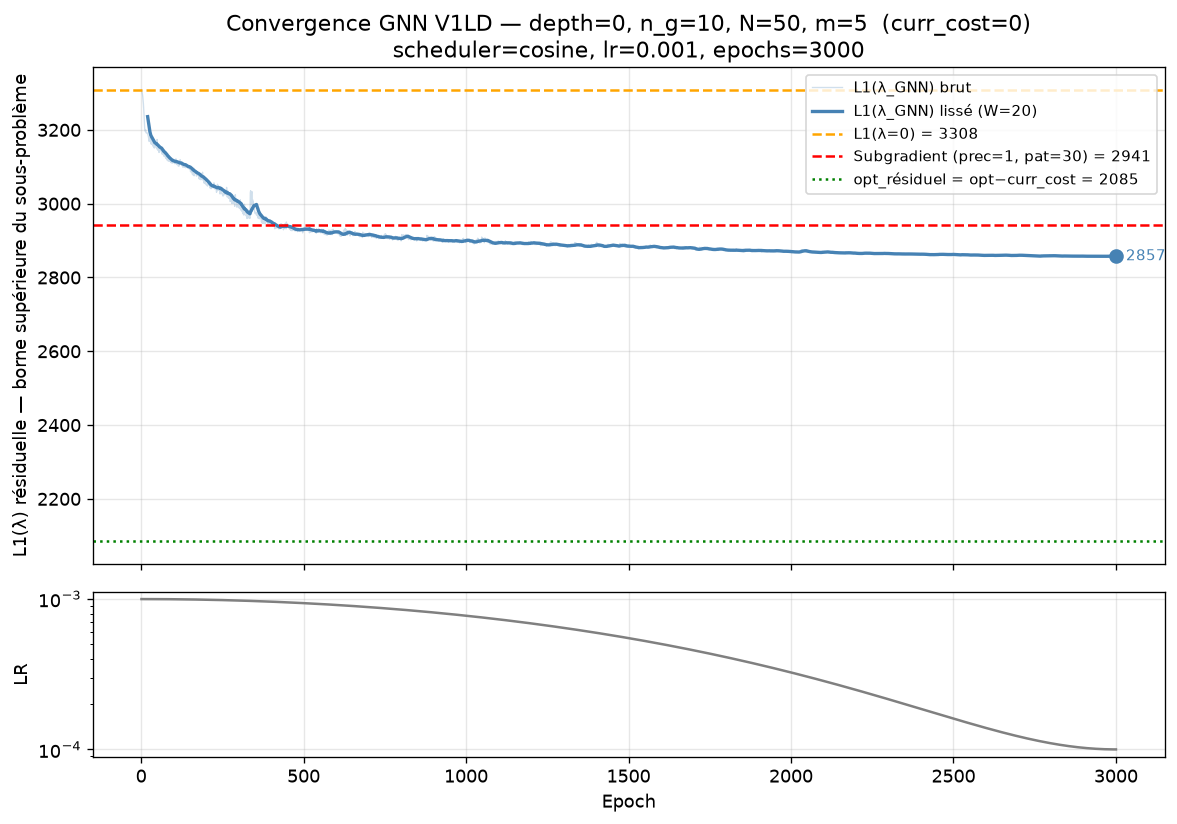

In [7]:
epochs_h = [h[0] for h in history]
l1_h     = [h[1] for h in history]
lr_h     = [h[2] for h in history]

W = 20
l1_smooth = np.convolve(l1_h, np.ones(W)/W, mode="valid")
ep_smooth = epochs_h[W-1:]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7),
                                gridspec_kw={"height_ratios": [3, 1]},
                                sharex=True)

ax1.plot(epochs_h, l1_h, alpha=0.25, color="steelblue", lw=0.8, label="L1(λ_GNN) brut")
ax1.plot(ep_smooth, l1_smooth, color="steelblue", lw=2,
         label=f"L1(λ_GNN) lissé (W={W})")

ax1.axhline(l1_init,      color="orange", lw=1.5, ls="--",
            label=f"L1(λ=0) = {l1_init:.0f}")
ax1.axhline(ref_subgrad,  color="red",    lw=1.5, ls="--",
            label=f"Subgradient (prec={PRECISION}, pat={PATIENCE}) = {ref_subgrad:.0f}")
# opt_residual = opt − curr_cost : borne inférieure du résidu (doit être ≤ toute L1 valide)
ax1.axhline(opt_residual, color="green",  lw=1.5, ls=":",
            label=f"opt_résiduel = opt−curr_cost = {opt_residual:.0f}")

ax1.scatter([epochs_h[-1]], [final_l1], color="steelblue", s=60, zorder=5)
ax1.annotate(f"  {final_l1:.0f}", (epochs_h[-1], final_l1),
             va="center", fontsize=9, color="steelblue")

ax1.set_ylabel("L1(λ) résiduelle — borne supérieure du sous-problème")
ax1.set_title(
    f"Convergence GNN V1LD — depth={depth}, n_g={g.n_g}, N={g.N}, m={g.m}  "
    f"(curr_cost={curr_cost:.0f})\n"
    f"scheduler={CFG['scheduler']}, lr={CFG['lr']}, epochs={CFG['n_epochs']}"
)
ax1.legend(loc="upper right", fontsize=9)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))
ax1.grid(True, alpha=0.3)

ax2.semilogy(epochs_h, lr_h, color="gray", lw=1.5)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("LR")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(REPO / "gnn" / "convergence_v1ld.png", bbox_inches="tight")
plt.show()

## 7. (Optionnel) Comparer plusieurs configs

Config : cosine lr=1e-3
  cosine lr=1e-3        final=2895.32
Config : cosine lr=3e-3
  cosine lr=3e-3        final=2879.63
Config : step lr=1e-3
  step lr=1e-3          final=2899.97
Config : aucun lr=1e-4
  aucun lr=1e-4         final=2919.57


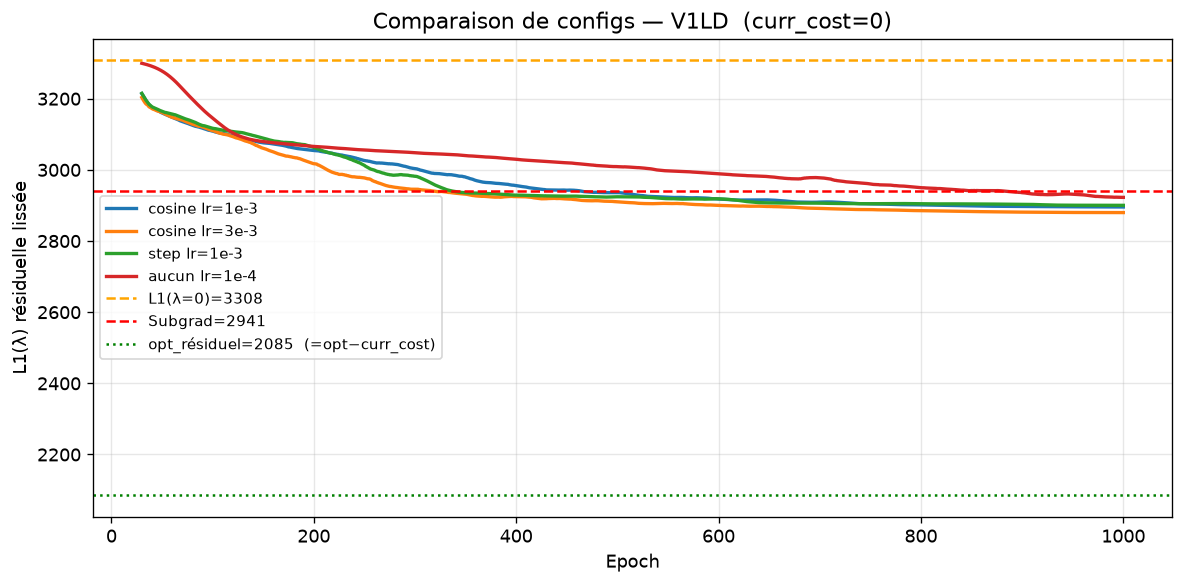

In [8]:
def run_config(cfg, data, seed=42):
    torch.manual_seed(seed)
    model_c   = GNN(m=data.m).to(data.x.device)
    optimizer = torch.optim.Adam(model_c.parameters(), lr=cfg["lr"])
    n_epochs  = cfg["n_epochs"]

    if cfg["scheduler"] == "cosine":
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=n_epochs, eta_min=cfg.get("eta_min", 1e-5))
    elif cfg["scheduler"] == "step":
        sched = torch.optim.lr_scheduler.StepLR(
            optimizer, step_size=cfg["step_size"], gamma=cfg["gamma"])
    else:
        sched = None

    hist = []
    for epoch in range(1, n_epochs + 1):
        model_c.train(); optimizer.zero_grad()
        lam  = model_c(data)
        loss = lagrangian_v1ld(lam, data)
        loss.backward(); optimizer.step()
        if sched: sched.step()
        hist.append((epoch, loss.item()))

    print(f"  {cfg['label']:20s}  final={hist[-1][1]:.2f}")
    return hist


CONFIGS = [
    dict(label="cosine lr=1e-3",  n_epochs=1000, lr=1e-3, scheduler="cosine", eta_min=1e-5),
    dict(label="cosine lr=3e-3",  n_epochs=1000, lr=3e-3, scheduler="cosine", eta_min=1e-5),
    dict(label="step lr=1e-3",    n_epochs=1000, lr=1e-3, scheduler="step",   step_size=300, gamma=0.3),
    dict(label="aucun lr=1e-4",   n_epochs=1000, lr=1e-4, scheduler="none"),
]

results = {}
for cfg in CONFIGS:
    print(f"Config : {cfg['label']}")
    results[cfg["label"]] = run_config(cfg, data)

fig, ax = plt.subplots(figsize=(10, 5))
colors  = plt.cm.tab10.colors

W = 30
for (label, hist), color in zip(results.items(), colors):
    ep   = [h[0] for h in hist]
    vals = [h[1] for h in hist]
    sm   = np.convolve(vals, np.ones(W)/W, mode="valid")
    ax.plot(ep[W-1:], sm, color=color, lw=2, label=label)

ax.axhline(l1_init,      color="orange", lw=1.5, ls="--", label=f"L1(λ=0)={l1_init:.0f}")
ax.axhline(ref_subgrad,  color="red",    lw=1.5, ls="--", label=f"Subgrad={ref_subgrad:.0f}")
ax.axhline(opt_residual, color="green",  lw=1.5, ls=":",
           label=f"opt_résiduel={opt_residual:.0f}  (=opt−curr_cost)")

ax.set_xlabel("Epoch"); ax.set_ylabel("L1(λ) résiduelle lissée")
ax.set_title(f"Comparaison de configs — V1LD  (curr_cost={curr_cost:.0f})")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(REPO / "gnn" / "convergence_compare_v1ld.png", bbox_inches="tight")
plt.show()

## 8. (Optionnel) Sanity check : solveur knapsack multi-dimensionnel

Vérifier que `_solve_zeta_multi_bb` donne la solution optimale sur un petit exemple.

In [9]:
# ── Instance jouet : 3 items, 2 contraintes ────────────────────────────────────
# Profits
cost_toy = np.array([10.0, 6.0, 4.0], dtype=np.float32)
# Poids (2, 3) : A[j, k]
A_toy    = np.array([[2.0, 1.0, 3.0],
                     [1.0, 2.0, 2.0]], dtype=np.float32)
# Capacités
b_toy    = np.array([4.0, 4.0], dtype=np.float32)

val_bb, x_bb = _solve_zeta_multi_bb(cost_toy, A_toy, b_toy)

print("Résultat B&B multi-dim :")
print(f"  valeur = {val_bb:.2f}  (attendu 16.0 : items 0+1)")
print(f"  x*     = {x_bb}")

# Vérification de la faisabilité
cap_used = A_toy @ x_bb
print(f"  capacité utilisée : {cap_used} ≤ {b_toy} ? {np.all(cap_used <= b_toy + 1e-6)}")

Résultat B&B multi-dim :
  valeur = 16.00  (attendu 16.0 : items 0+1)
  x*     = [1. 1. 0.]
  capacité utilisée : [3. 3.] ≤ [4. 4.] ? True
